In [19]:
import os
from dotenv import load_dotenv, find_dotenv
from google import genai
from google.genai import types

load_dotenv(find_dotenv())

# Reads GEMINI_API_KEY from your .env file (or you can pass api_key=... explicitly)
client = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))
if os.environ.get("GEMINI_API_KEY"):
    print("Both API Key variable is exists")
else:
    raise ValueError("GEMINI_API_KEY not found")
from langchain_core.messages import HumanMessage,AIMessage,SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser,PydanticOutputParser
from pydantic import BaseModel
llm_genai=ChatGoogleGenerativeAI(model="gemini-3.5-flash",temperature=0.7)

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.
Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


Both API Key variable is exists


In [12]:
llm_genai.invoke("Send an email to kalaiyarasan200411@gmail.com")

AIMessage(content=[{'type': 'text', 'text': "I cannot directly send emails from here, but I can draft the email for you so you can copy and paste it into your email provider (like Gmail, Outlook, etc.). \n\nIf you'd like me to draft it, please let me know:\n1. What is the **subject** of the email?\n2. What **key information or message** would you like to include?\n3. What **tone** should it have (e.g., professional, friendly, formal)?", 'extras': {'signature': 'EssJCsgJAWkUfRP1xYKhllYaHQiY1fuBsnU59Jh1OebK9/d5XT+5CHbxuvHhV8y1pgphPPhZ2BOZAQV4T2R/2sxblhEjRPNXydTw033ZBIpYu6P1K/ZZ2PwXhdOYOb7hXacM8sbbqUnCGKIaaqH60I1Cy214HTty7BzWoIzrBsPP6tINvJSqEjclqSIh/u/1CwDvaSAXOOPjBqCvy5Dg61AWE2LnymRCUDNOnz0i0ekjjNn3UnpFubGcErehkCDqlAbCzPHogyR9GIUFdOTkjfVH6Sx5BzmdJ3Awz5XCuGw8nhInHwc1to+/TWcb8ypK+00sA6YunH7fJkEzSfvltC+QWkEupAQrl7ovNC+FU3PjG/4J8RGAf9bRKmaSolN3Jykd5go9W7dj5qNm1ow1exTi9gGTqqLQYLx6riGlRAwHdnPLWa8siI38vdib1efRzXsdxy7Jli8VxoqloSbvjpbMyfd5FlYRImjc1fyW6Gsj5SLBa9Y+ZEroOThPI8Pt/Jmx3BjfYdOMPPIcvvVbU0

# Tools

In [20]:
from jedi import api
# Tool-1 [News Search Tool]
from langchain_community.tools import DuckDuckGoSearchResults

search_tool=DuckDuckGoSearchResults()

#Tool -2 [Wikipedia Tool]
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
wikipedia_tool=WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(),description="This is a tool to search wikipedia")

#Tool -3 [Custom Enterprise Tool]

from langchain.tools import tool

@tool
def enterprise_tool(query:str)->str:
    """This is the tool to send email to employees"""
    return "Email sent"

In [21]:
Toolkit=[search_tool,wikipedia_tool,enterprise_tool]
Toolkit

[DuckDuckGoSearchResults(api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(description='This is a tool to search wikipedia', api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'c:\\Users\\kalai\\Desktop\\LangChain_Project\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_tool', description='This is the tool to send email to employees', args_schema=<class 'langchain_core.utils.pydantic.enterprise_tool'>, func=<function enterprise_tool at 0x000001DDAA70A2A0>)]

# ReAct Agent

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


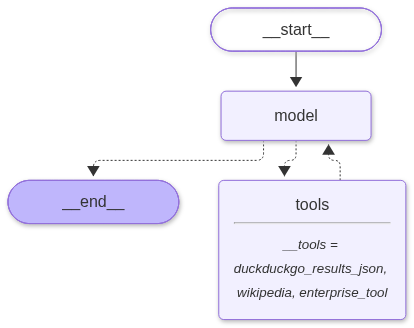

In [22]:
from langchain.agents import create_agent
from langchain_google_genai import ChatGoogleGenerativeAI

model=ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.7,
    max_tokens=1000,
    timeout=30
)
agent=create_agent(model,tools=Toolkit)
agent

# ReAct Agent Invoke with Streams

In [23]:
example_query="Give me the latest news about stock market"

events=agent.stream(
    {"messages":[("user",example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Give me the latest news about stock market


GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\nPlease retry in 17h33m7.72620662s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://aistudio.google.com/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Generate content

# Manually Binding The LLM with Tools

In [ ]:
# Without Binding
llm_genai.invoke("What's the latest news about stock market?")

AIMessage(content=[{'type': 'text', 'text': 'Because stock market prices and headlines change second-by-second, I can\'t provide a live, real-time ticker feed. However, here is a summary of the **main economic themes and news drivers** currently influencing the global and U.S. stock markets:\n\n---\n\n### 1. The Federal Reserve & Interest Rates\n* **Rate Cut Expectations:** Markets remain highly sensitive to signals from Federal Reserve Chair Jerome Powell and other policymakers regarding when and how much interest rates will be cut. \n* **"Higher for Longer":** Stronger-than-expected economic data or sticky inflation numbers often lead markets to pull back, as investors fear the Fed will keep interest rates high for a longer period.\n\n### 2. Big Tech & The AI Boom\n* **The "Magnificent Seven":** Heavyweight tech companies (Nvidia, Microsoft, Apple, Alphabet, Amazon, Meta, and Tesla) continue to account for a significant portion of the gains in indices like the S&P 500 and the Nasdaq.

In [18]:
#With Binding
llm_binded=llm_genai.bind_tools(Toolkit)
llm_binded.invoke("What's the latest news about stock market")

AIMessage(content=[], additional_kwargs={'function_call': {'name': 'duckduckgo_results_json', 'arguments': '{"query": "latest stock market news today"}'}, '__gemini_function_call_thought_signatures__': {'call_13740072606486966877': 'Ev4DCvsDAWkUfROxk2LGU1UmixZlhtalDi2cXvqh/fdGk97DcR812ibaFZKDloDE6odm4pr5nCNgj0/V+Yncr053cfk0RMOWntuUNepw+8nrJIl2Yx2PptdtkAbjPbOJ49vp0lZ8S7O3xJlNdDFdMdBOxqVW+/0Y5P19JFC+UDwIli/DkIXSQaUSh3M63RMYiAWQVtbH3cvHQ4Og7KpGU7VjOtQEAR1sgRi+nBtTLyzXrT924V0tNEi96lv7qYcI/lph67UtB8l85LmWiENzUs2gB24MdlhHIEsBLTFyEhThx3KqwR4IP5xfW6Wxfnt6A9xrQAZlm9giNK3YP8TMspQ/tWvwA5+3I/YqiQIRLCSSRPzbgo0IAADbXJ4dehtd4aXsar7qpifmCQqtGhq99je9tJ/zDqFW/um7LjKBy9PtKWattUgucqMysvhgrXRsdFsJsBKRU941wVRhabcsiRsFujxOSf/VFYceNtJg7Oa+U9c/tN6hMbqmahiODK0KNOKNMAodauUsqng9Rpp5cNfbrgRjzE6AyhECG4DJ3fRl2WuANvbeLxAoI1M0GM0A1MrwO+qPpEdVt+7O+A+b7srUzyqWWQd4qa1+vc9Z/IuYWoRaRAbVWjbHWLaj5oIFnkamffJ5jErXbmDOFtvEdszVxKPGmqoTlL7Y5nM+nzmU'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.6-flash', 